**Rigorous Distillation Column: Benzene-Toluene**

In this tutorial we model a rigorous, equilibrium stage distillation column for benzene-toluene with the IDAES `TrayColumn` model, and validate it stage by stage against DWSIM's Distillation Column (Peng-Robinson property package). The column is the one sized with the shortcut method in the Shortcut Column tutorial.

On every stage the model solves the **MESH** equations: **M**aterial balances, phase **E**quilibrium (Peng-Robinson fugacities), mole fraction **S**ums and en**H**alpy balances,

$$L_{n-1} x_{j,n-1} + V_{n+1} y_{j,n+1} + F_n z_{j,n} = L_n x_{j,n} + V_n y_{j,n} \qquad \hat{f}^{\,V}_{j,n} = \hat{f}^{\,L}_{j,n}$$

### Column specifications:

| | |
|---|---|
| Feed | 1 kg/s, 50/50 mol benzene/toluene, 300 K, 1.01325 bar, on stage 8 |
| Stages | 13: stage 1 total condenser, stages 2–12 trays, stage 13 reboiler |
| Specifications | reflux ratio 1.5 and bottoms flow 5.8 mol/s |
| Pressure | 1.01325 bar at the condenser, 10 Pa pressure drop to the reboiler |

DWSIM counts the condenser and reboiler as stages, the IDAES `TrayColumn` counts only the trays between them: **IDAES tray k is DWSIM stage k + 1**, so the feed stage 8 is `feed_tray_location=7`.

---

> **Solving strategy**
>
> `distillation_column.py` reaches the solution in four steps:
> 1. initialize tray by tray with the feed near its bubble point (365 K), and a boilup ratio guess;
> 2. tighten the smoothing parameters of the Peng-Robinson vapor-liquid complementarity (`eps_t`, `eps_z`) from their default of 1 mol/s to 10⁻⁴ mol/s. With the default, a phase that should vanish lingers; for example the total condenser outlet at its bubble point keeps about 10 % vapor;
> 3. step the feed temperature down to the actual subcooled 300 K;
> 4. replace the boilup ratio with the DWSIM specification, the bottoms flow.

> **Shortcut vs rigorous**
>
> The shortcut column predicted 12.6 stages for 99 mol % benzene in the distillate and 1 mol % in the bottoms. With 13 stages the rigorous column only reaches 93 % and 5.9 %. The shortcut evaluated the relative volatility at the subcooled feed (α ≈ 3.3), well above its value inside the column (α ≈ 2.4), so it underestimated the stages needed. This is why shortcut designs are checked with a rigorous column.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


## Setting up and solving the flowsheet

The flowsheet is Feed → TrayColumn → distillate and bottoms Products, built in `distillation_column.py`.

In [2]:
from distillation_column import setup_distillation_model, report_distillation_properties

# Create and solve the model
model, results = setup_distillation_model(
    flow_mass=1.0,  # kg/s
    mole_frac={"benzene": 0.5, "toluene": 0.5},
    temperature=300,  # K
    pressure=101325,  # Pa
    number_of_stages=13,  # DWSIM numbering
    feed_stage=8,  # DWSIM numbering
    reflux_ratio=1.5,
    bottoms_flow=5.8,  # mol/s
    condenser_pressure=101325,  # Pa
    column_pressure_drop=10,  # Pa
)
print(results.solver.termination_condition)

prop = report_distillation_properties(model)

The initial DOF is 20
The final DOF is 0
optimal

Unit : fs.feed                                                             Time: 0.0
------------------------------------------------------------------------------------
    Stream Table
                                    Units        Outlet  
    Total Molar Flowrate         mole / second     11.747
    Total Mole Fraction benzene  dimensionless    0.50000
    Total Mole Fraction toluene  dimensionless    0.50000
    Temperature                         kelvin     300.00
    Pressure                            pascal 1.0132e+05

Unit : fs.distillate                                                       Time: 0.0
------------------------------------------------------------------------------------
    Stream Table
                                    Units         Inlet  
    Total Molar Flowrate         mole / second     5.9474
    Total Mole Fraction benzene  dimensionless    0.92996
    Total Mole Fraction toluene  dimensionless   0.07

In [3]:
# Visualize (if needed)
model.fs.visualize("Distillation Column Model")

'idaes.co re.util.diagnostics_tools.diagnostics_toolbox.DiagnosticsToolbox'.
Please update your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
'idaes.core.util.diagnostics_tools.diagnostics_toolbox.CONFIG'. Please update
your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
2026-11-07 11:00:47 [INFO] idaes.idaes_ui.fv.fsvis: Started visualization server
2026-11-07 11:00:47 [INFO] idaes.idaes_ui.fv.fsvis: Saving flowsheet to default file 'Distillation Column Model.json' in current directory (c:\Users\VirajDesai\Downloads\Personal\Github\IDAES-PSE-Examples\Distillation Column)
2026-11-07 11:00:47 [WARNING] idaes.core.base.process_base: Could not serialize stream table: Unit model fs.column does not have the standard Port names (inlet and outlet). Please contact the unit model developer to develop a unit specific stream table.
2026-11-07 11:00:47 [WARNING] idaes.idaes_ui.fv.flowsheet: Port is neither a feed nor a product: nam

VisualizeResult(store=<idaes_ui.fv.persist.FileDataStore object at 0x00000240B940FEF0>, port=50619, server=<idaes_ui.fv.model_server.FlowsheetServer object at 0x00000240FE946D20>, save_diagram=<bound method SaveDiagramScreenshot.save_diagram_screenshot of <idaes_ui.fv.save_diagram_screenshot.SaveDiagramScreenshot object at 0x00000240B6CA7620>>)

## Validation against DWSIM

The DWSIM results and converged stage profiles are read directly from the solved `.dwxmz` file.

In [4]:
from distillation_column import read_dwsim_results, compare_with_dwsim, compare_profiles

dwsim, dwsim_stages = read_dwsim_results("DWSim Distillation Column Model.dwxmz")
compare_with_dwsim(model, dwsim)

,IDAES,DWSIM,Difference,Error (%)
Distillate flow (mol/s),5.947412,5.947412,9.999201e-11,1.681269e-09
Bottoms flow (mol/s),5.800000,5.800000,0.000000e+00,0.000000e+00
Distillate benzene mole fraction,0.929959,0.929965,-5.910496e-06,-6.355613e-04
Bottoms benzene mole fraction,0.059112,0.059114,-2.020988e-06,-3.418794e-03
Distillate temperature (K),354.287132,354.286893,2.388649e-04,6.742132e-05
Bottoms temperature (K),381.130989,381.130717,2.723497e-04,7.145834e-05
Condenser duty (kW),457.235837,457.219720,1.611772e-02,3.525159e-03
Reboiler duty (kW),574.614293,574.589897,2.439555e-02,4.245732e-03
Boilup ratio,2.967512,2.967517,-5.127873e-06,-1.728001e-04


In [5]:
compare_profiles(model, dwsim_stages)

,T IDAES (K),T DWSIM (K),T difference (K),x IDAES,x DWSIM
Stage,,,,,
1,354.287132,354.287,0.000132,0.929959,0.929965
2,356.258587,356.258,0.000587,0.841374,0.841385
3,358.620447,358.620,0.000447,0.741920,0.741934
4,361.042236,361.041,0.001236,0.646893,0.646907
5,363.170590,363.170,0.000590,0.568701,0.568714
6,364.808609,364.808,0.000609,0.511654,0.511664
7,365.948100,365.948,0.000100,0.473477,0.473484
8,366.687244,366.687,0.000244,0.449347,0.449353
9,369.422492,369.422,0.000492,0.364095,0.364102


## Stage profiles

IDAES results are shown as lines and DWSIM results as markers. Stage 1 is the condenser and stage 13 the reboiler.

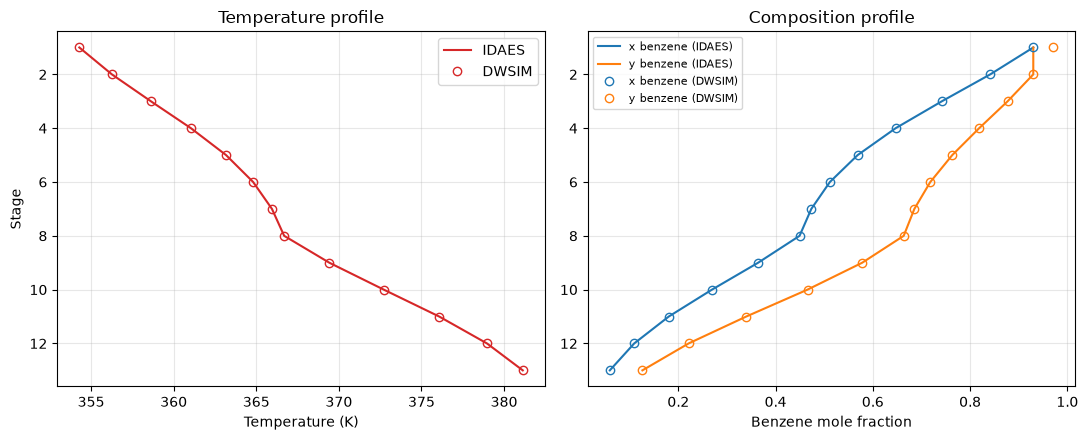

2026-11-07 11:02:42 [WARNING] idaes.core.base.process_base: Could not serialize stream table: Unit model fs.column does not have the standard Port names (inlet and outlet). Please contact the unit model developer to develop a unit specific stream table.
2026-11-07 11:02:42 [WARNING] idaes.idaes_ui.fv.flowsheet: Port is neither a feed nor a product: name=reflux feed-expr=re.compile('^in_|^feed_|^inlet_|^in$|^feed$|^inlet$|_in$|_feed$|_inlet$', re.IGNORECASE) product-expr=re.compile('^out_|^prod_|^outlet_|^out$|^prod$|^outlet$|_out$|_prod$|_outlet$', re.IGNORECASE)
2026-11-07 11:02:42 [WARNING] idaes.idaes_ui.fv.flowsheet: Port is neither a feed nor a product: name=vapor_reboil feed-expr=re.compile('^in_|^feed_|^inlet_|^in$|^feed$|^inlet$|_in$|_feed$|_inlet$', re.IGNORECASE) product-expr=re.compile('^out_|^prod_|^outlet_|^out$|^prod$|^outlet$|_out$|_prod$|_outlet$', re.IGNORECASE)


In [ ]:
import matplotlib.pyplot as plt
from distillation_column import profiles

prof = profiles(model)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
ax1.plot(prof["Temperature (K)"], prof.index, color="tab:red", label="IDAES")
ax1.plot(dwsim_stages["Temperature (K)"], dwsim_stages.index, "o", color="tab:red", mfc="none", label="DWSIM")
ax1.set_xlabel("Temperature (K)")
ax1.set_ylabel("Stage")
ax1.set_title("Temperature profile")
ax1.invert_yaxis()
ax1.legend()
ax1.grid(alpha=0.3)
ax2.plot(prof["x benzene"], prof.index, color="tab:blue", label="x benzene (IDAES)")
ax2.plot(prof["y benzene"], prof.index, color="tab:orange", label="y benzene (IDAES)")
ax2.plot(dwsim_stages["x benzene"], dwsim_stages.index, "o", color="tab:blue", mfc="none", label="x benzene (DWSIM)")
ax2.plot(dwsim_stages["y benzene"], dwsim_stages.index, "o", color="tab:orange", mfc="none", label="y benzene (DWSIM)")
ax2.set_xlabel("Benzene mole fraction")
ax2.set_title("Composition profile")
ax2.invert_yaxis()
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()